# 03 · Matriz de riesgos LINDDUN de la DPIA

**Objetivo:** visualizar la evaluación de riesgos de la DPIA (informe final, sección 2, pasos 3 y 5), antes y después de aplicar las medidas de mitigación.

**Fuente de los valores:** la probabilidad (P) y el impacto (I) de cada riesgo se asignan por juicio experto en escala 1–5, calibrados con la evidencia empírica del notebook 01 (por ejemplo, R1 y R2 con el 22.4 % de re-identificación y las 7,396 matrículas con $k=1$). El nivel es $R = P \times I$: **bajo** 1–6, **medio** 8–12, **alto** 15–25. El riesgo residual supone implementadas las medidas propuestas para producción (M11–M18).

In [1]:
import pandas as pd

riesgos = pd.DataFrame([
    ("R1", "Linking: cruce por QI + curso + semestre", 5, 5, 1, 5),
    ("R2", "Identifying: registros con k = 1", 5, 5, 1, 5),
    ("R3", "Data disclosure: homogeneidad en disability", 4, 5, 1, 5),
    ("R4", "Detecting: inferencia de pertenencia por consultas", 3, 4, 2, 3),
    ("R5", "Data disclosure: proxies en el modelo", 2, 4, 2, 3),
    ("R6", "Unawareness: perfilado sin conocimiento ni oposición", 4, 4, 2, 4),
    ("R7", "Non-compliance: uso punitivo e impacto dispar", 3, 5, 2, 4),
    ("R8", "Non-compliance: consentimiento no libre", 3, 4, 2, 3),
    ("R9", "Data disclosure: brecha de seguridad", 3, 5, 2, 5),
    ("R10", "Non-repudiation: falta de trazabilidad", 3, 3, 1, 3),
    ("R11", "Data disclosure: modo pedagógico activo", 4, 4, 1, 4),
], columns=["id", "amenaza", "P_inh", "I_inh", "P_res", "I_res"])


def nivel(r: int) -> str:
    return "alto" if r >= 15 else "medio" if r >= 8 else "bajo"


riesgos["R_inh"] = riesgos["P_inh"] * riesgos["I_inh"]
riesgos["R_res"] = riesgos["P_res"] * riesgos["I_res"]
riesgos["nivel_inh"] = riesgos["R_inh"].map(nivel)
riesgos["nivel_res"] = riesgos["R_res"].map(nivel)
print("Riesgos altos: inherente =", (riesgos["nivel_inh"] == "alto").sum(), "| residual =", (riesgos["nivel_res"] == "alto").sum())
riesgos

Riesgos altos: inherente = 7 | residual = 0


,id,amenaza,P_inh,I_inh,P_res,I_res,R_inh,R_res,nivel_inh,nivel_res
0,R1,Linking: cruce por QI + curso + semestre,5,5,1,5,25,5,alto,bajo
1,R2,Identifying: registros con k = 1,5,5,1,5,25,5,alto,bajo
2,R3,Data disclosure: homogeneidad en disability,4,5,1,5,20,5,alto,bajo
3,R4,Detecting: inferencia de pertenencia por consu...,3,4,2,3,12,6,medio,bajo
4,R5,Data disclosure: proxies en el modelo,2,4,2,3,8,6,medio,bajo
5,R6,Unawareness: perfilado sin conocimiento ni opo...,4,4,2,4,16,8,alto,medio
6,R7,Non-compliance: uso punitivo e impacto dispar,3,5,2,4,15,8,alto,medio
7,R8,Non-compliance: consentimiento no libre,3,4,2,3,12,6,medio,bajo
8,R9,Data disclosure: brecha de seguridad,3,5,2,5,15,10,alto,medio
9,R10,Non-repudiation: falta de trazabilidad,3,3,1,3,9,3,medio,bajo


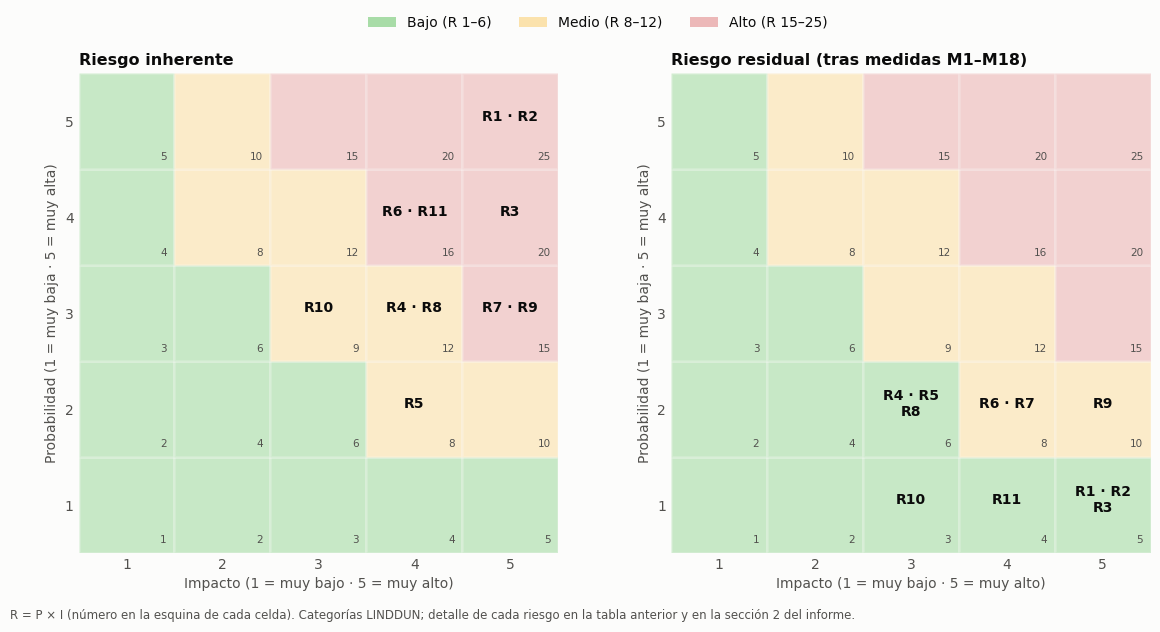

In [2]:
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

FIG_DIR = "../docs/figuras"
os.makedirs(FIG_DIR, exist_ok=True)

# Mismo sistema visual que el notebook 02.
SERIE_1, SERIE_2, NEUTRO = "#2a78d6", "#eb6834", "#898781"
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": TINTA_2, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})

# Colores de estado (bajo / medio / alto) como tinte de fondo; el texto va siempre en tinta.
NIVEL_COLOR = {"bajo": "#0ca30c", "medio": "#fab219", "alto": "#d03b3b"}


def matriz(ax, p_col, i_col, titulo):
    ax.grid(False)
    for p in range(1, 6):
        for i in range(1, 6):
            ax.add_patch(Rectangle((i - 0.5, p - 0.5), 1, 1, facecolor=NIVEL_COLOR[nivel(p * i)], alpha=0.22,
                                   edgecolor=FONDO, linewidth=2))
            ax.text(i + 0.42, p - 0.42, str(p * i), ha="right", va="bottom", fontsize=7.5, color=TINTA_2)
    for (p, i), grupo in riesgos.groupby([p_col, i_col]):
        ids = list(grupo["id"])
        texto = "\n".join(" · ".join(ids[k:k + 2]) for k in range(0, len(ids), 2))
        ax.text(i, p + 0.05, texto, ha="center", va="center", fontsize=10, fontweight="bold", color=TINTA)
    ax.set_xlim(0.5, 5.5)
    ax.set_ylim(0.5, 5.5)
    ax.set_xticks(range(1, 6))
    ax.set_yticks(range(1, 6))
    ax.set_aspect("equal")
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.tick_params(length=0)
    ax.set_xlabel("Impacto (1 = muy bajo · 5 = muy alto)")
    ax.set_ylabel("Probabilidad (1 = muy baja · 5 = muy alta)")
    ax.set_title(titulo)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.6))
matriz(ax1, "P_inh", "I_inh", "Riesgo inherente")
matriz(ax2, "P_res", "I_res", "Riesgo residual (tras medidas M1–M18)")
fig.legend(handles=[Patch(facecolor=NIVEL_COLOR[k], alpha=0.35, label=f"{k.capitalize()} ({r})")
                    for k, r in [("bajo", "R 1–6"), ("medio", "R 8–12"), ("alto", "R 15–25")]],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.07))
fig.text(0.01, -0.03, "R = P × I (número en la esquina de cada celda). Categorías LINDDUN; detalle de cada riesgo en la tabla anterior "
         "y en la sección 2 del informe.", fontsize=8.5, color=TINTA_2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/matriz_riesgos_linddun.png", dpi=200, bbox_inches="tight")
plt.show()